In [1]:

"""
CodeAlpha - Data Visualization

This notebook explores book ratings and prices using visualizations.
The dataset contains 20 books collected from the first page of
Books to Scrape.
"""

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("books.csv")

# Clean the price column
df["Price"] = (
    df["Price"]
    .astype("string")
    .str.replace("£", "", regex=False)
    .str.replace("Â", "", regex=False)
    .str.strip()
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# Convert rating labels into numbers
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_map)

# Keep valid rows for visualization
df = df.dropna(subset=["Price", "Rating"]).copy()

print(f"Books available for visualization: {len(df)}")


Books available for visualization: 20


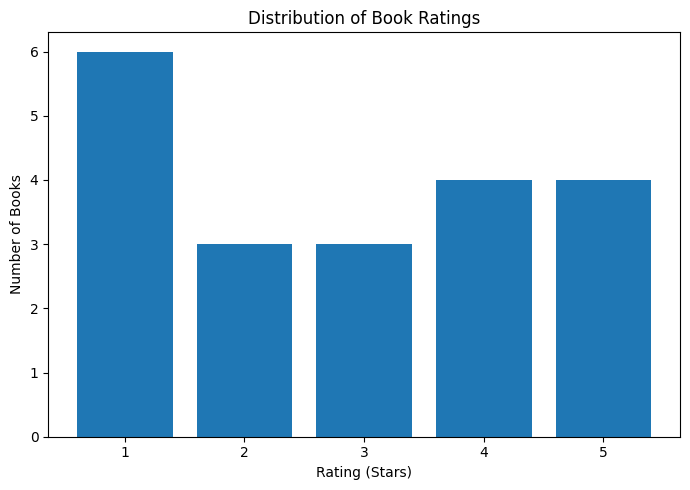

In [2]:

rating_counts = (
    df["Rating"]
    .value_counts()
    .sort_index()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

plt.figure(figsize=(7, 5))
plt.bar(rating_counts.index, rating_counts.values)

plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()


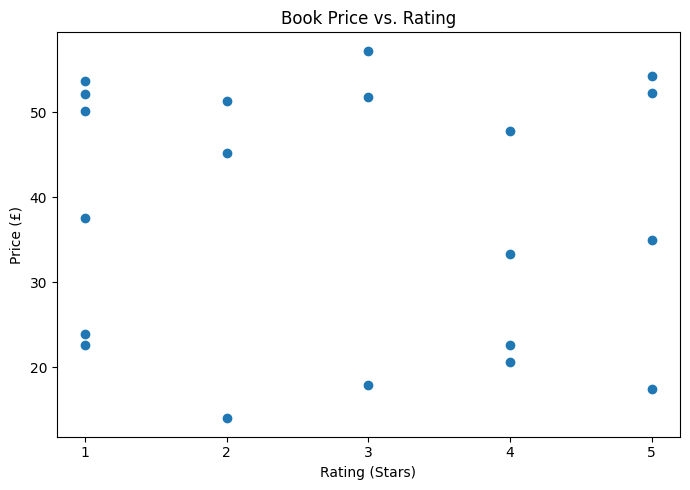

In [3]:

plt.figure(figsize=(7, 5))
plt.scatter(df["Rating"], df["Price"])

plt.xlabel("Rating (Stars)")
plt.ylabel("Price (£)")
plt.title("Book Price vs. Rating")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()


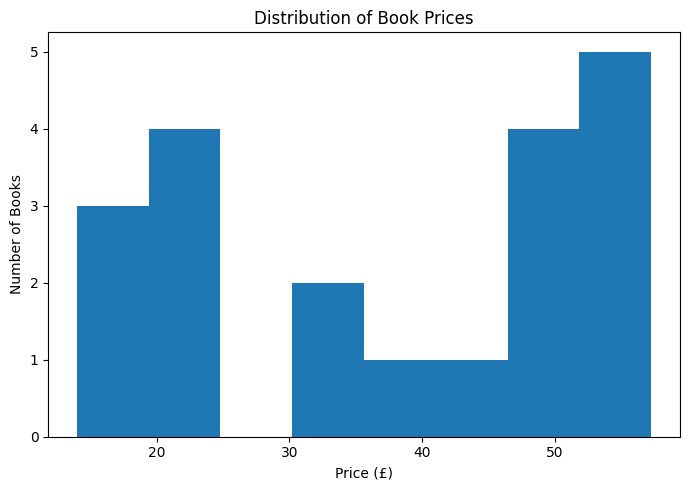

In [4]:

plt.figure(figsize=(7, 5))
plt.hist(df["Price"], bins=8)

plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Prices")
plt.tight_layout()
plt.show()



## Key Visualization Insights

- **Most common rating:** One-star books, with 6 books in this sample.
- **Average price:** £38.05.
- **Price range:** £13.99 to £57.25.
- **Average rating:** 2.85 out of 5.
- **Price and rating:** The Pearson correlation is approximately -0.076, indicating no clear linear association in this small sample.
- **Average price by rating:** Three-star books have the highest average price (£42.32), while four-star books have the lowest (£31.11).

**Limitation:** These findings describe only 20 books collected from the first page of the website. They should not be generalized to all books.
